# Lab 09: Satellite and Geospatial Data — GEE · COG · STAC

So far, we have used AWS ground stations—a few dozen points across Korea. But a digital twin needs data across a whole grid, including places with no stations. Satellites help fill these gaps with gridded observations, such as land surface temperature (LST).

Today we explore five tools: `rasterio` to read and write rasters, `COG` to read part of a cloud-hosted raster, `rioxarray` to work with raster coordinates, `STAC` to find satellite assets, and `Google Earth Engine (GEE)` to access satellite archives.

Finally, we extract `LST` at station locations and align it with Week 4’s 0.5° model grid, preparing an input feature for Week 8 machine learning.


## Learning Objectives

By the end of this lab you will be able to:

- Read and write rasters with rasterio, including their CRS, pixel locations, and missing values.
- Explain COGs and check that reading a small region gives the same values as a full read.
- Use rioxarray to work with coordinates, change the CRS, and clip a region.
- Build and search a local STAC catalog by location and date.
- Explain GEE’s role and read a basic MODIS LST query that requires authentication.
- Extract LST at station locations and align it with the 0.5° model grid for Week 8 machine learning.  


In [1]:

import os, sys, json, tempfile, datetime

import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

import rasterio
from rasterio.transform import from_origin, array_bounds
from rasterio.windows import from_bounds as window_from_bounds
from rasterio.enums import Resampling
import rioxarray            # registers the .rio accessor on xarray (side-effect import)
import xarray as xr

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11
rng = np.random.default_rng(0)          # reproducibility: fixed seed

# Today's outputs live only inside this temporary work folder
# (the course repository stays untouched; never commit binaries).
WORK = tempfile.mkdtemp(prefix="course410_wk09_")
print("work folder :", WORK)
print("python      :", sys.version.split()[0])
print("rasterio    :", rasterio.__version__, "| rioxarray:", rioxarray.__version__)


work folder : /var/folders/hh/w5xjnck119d_h0x6gxztgrwr0000gn/T/course410_wk09_gu8k2zc5
python      : 3.11.0
rasterio    : 1.4.3 | rioxarray: 0.19.0


---
## 1. Anatomy of a raster — CRS · affine transform · band · nodata

A satellite image is a 2D grid of numbers. To place it on a map, we need four pieces of information:

| Element | Meaning | Our example |
|---|---|---|
| CRS | The coordinate reference system used on the map | EPSG:4326 (longitude/latitude) |
| Affine transform | Links each pixel to its map location | Grid origin and pixel size |
| Band | One layer of measured values | 1 band: LST |
| nodata | A special value for missing data | -9999 |


The affine transform tells us where each pixel is on the map. For a grid with no rotation:


$$
\text{lon} = c + a\,(\text{col}+0.5), \qquad
\text{lat} = f + e\,(\text{row}+0.5)
$$

- $(c, f)$: the grid’s upper-left corner
- $(a, e)$: pixel size; e is usually negative because rows go downward
- +0.5: moves from the pixel’s corner to its center

First, we create a synthetic LST image over Korea in kelvin (K). Each pixel’s value follows a known formula based on latitude, longitude, and a gentle wave, so we can check our sampling results exactly later.


In [2]:

# --- Raster grid definition (Korean peninsula domain, EPSG:4326) ---
H = W = 300                              # 300 x 300 pixels
RES_DEG = 0.02                           # pixel size 0.02 deg (~2.2 km)
LON_W, LAT_N = 124.5, 39.0               # top-left (north-west) corner
transform = from_origin(LON_W, LAT_N, RES_DEG, RES_DEG)   # west, north, xsize, ysize
NODATA = -9999.0

# (lat, lon) of each pixel centre -- computed with the same +0.5 rule as the transform
rows, cols = np.mgrid[0:H, 0:W]
lat_c = LAT_N - (rows + 0.5) * RES_DEG
lon_c = LON_W + (cols + 0.5) * RES_DEG

def true_lst(lat, lon):
    # A known analytic LST (K): cooler to the north, slightly warmer to the east,
    # plus a gentle east-west wave.
    base     = 305.0
    lat_grad = -1.8 * (lat - 36.0)                 # -1.8 K per degree northward
    lon_grad =  0.4 * (lon - 128.0)
    wave     =  1.5 * np.sin(2 * np.pi * lon / 2.0)
    return base + lat_grad + lon_grad + wave

lst = true_lst(lat_c, lon_c).astype("float32")

# Plant a 'cloud-covered gap' as nodata (over the north-western sea, away from stations).
lst[10:45, 30:85] = NODATA
n_nodata = int((lst == NODATA).sum())
print(f"raster size: {H}x{W} pixels, resolution {RES_DEG} deg (~{RES_DEG*111:.1f} km)")
print(f"domain: lon {LON_W}-{LON_W+W*RES_DEG} degE, lat {LAT_N-H*RES_DEG}-{LAT_N} degN")
print(f"nodata (cloud) pixels: {n_nodata}")
print(f"valid LST range: {lst[lst!=NODATA].min():.1f} - {lst[lst!=NODATA].max():.1f} K")


raster size: 300x300 pixels, resolution 0.02 deg (~2.2 km)
domain: lon 124.5-130.5 degE, lat 33.0-39.0 degN
nodata (cloud) pixels: 1925
valid LST range: 297.1 - 312.9 K


In [3]:

# --- Writing a GeoTIFF with rasterio: array + CRS + transform + nodata together ---
tif_path = os.path.join(WORK, "lst_scene.tif")
with rasterio.open(
        tif_path, "w", driver="GTiff",
        height=H, width=W, count=1, dtype="float32",
        crs="EPSG:4326", transform=transform, nodata=NODATA) as dst:
    dst.write(lst, 1)                    # write into band 1

# Reopen and inspect the profile (metadata) -- it is not just the array that is stored.
with rasterio.open(tif_path) as src:
    print("driver   :", src.driver)
    print("size     :", src.width, "x", src.height, "| bands:", src.count)
    print("dtype    :", src.dtypes[0], "| nodata:", src.nodata)
    print("CRS      :", src.crs)
    print("transform:", src.transform)
    print("bounds   :", src.bounds)      # (left, bottom, right, top)


driver   : GTiff
size     : 300 x 300 | bands: 1
dtype    : float32 | nodata: -9999.0
CRS      : EPSG:4326
transform: | 0.02, 0.00, 124.50|
| 0.00,-0.02, 39.00|
| 0.00, 0.00, 1.00|
bounds   : BoundingBox(left=124.5, bottom=33.0, right=130.5, top=39.0)


In [4]:

# Verify the affine transform: does the pixel-index <-> Earth-coordinate round trip
# agree with our formula?
with rasterio.open(tif_path) as src:
    # (a) the center Earth coordinate of pixel (row=100, col=150)
    r0, c0 = 100, 150
    lon_xy, lat_xy = src.xy(r0, c0)                 # rasterio: pixel centre coordinate
    my_lon = LON_W + (c0 + 0.5) * RES_DEG
    my_lat = LAT_N - (r0 + 0.5) * RES_DEG
    print(f"pixel({r0},{c0}) center  rasterio=({lon_xy:.4f},{lat_xy:.4f})  "
          f"formula=({my_lon:.4f},{my_lat:.4f})")

    # (b) the reverse: Earth coordinate -> pixel index
    row_i, col_i = src.index(126.98, 37.57)         # near Seoul
    print(f"coordinate (126.98,37.57) -> pixel (row={row_i}, col={col_i})")

assert abs(lon_xy - my_lon) < 1e-9 and abs(lat_xy - my_lat) < 1e-9
print("-> the affine transform maps pixel <-> Earth coordinates exactly as our formula does.")


pixel(100,150) center  rasterio=(127.5100,36.9900)  formula=(127.5100,36.9900)
coordinate (126.98,37.57) -> pixel (row=71, col=124)
-> the affine transform maps pixel <-> Earth coordinates exactly as our formula does.


scene shown: cooler towards higher latitude (upwards); the grey rectangle is the cloud gap


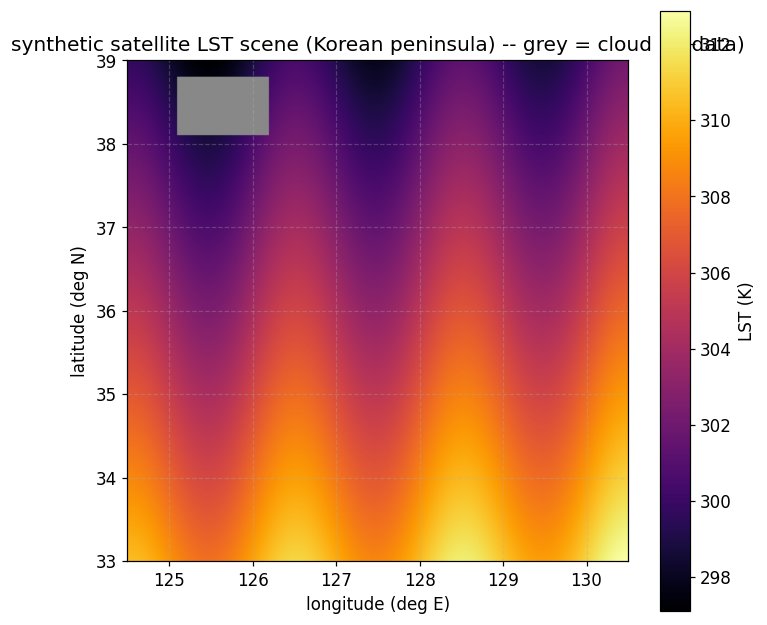

In [5]:

# Map the synthetic LST scene. nodata (cloud) is masked out and drawn in grey.
with rasterio.open(tif_path) as src:
    arr = src.read(1, masked=True)                  # nodata becomes a masked array
    left, bottom, right, top = src.bounds

fig, ax = plt.subplots(figsize=(6.6, 6.0))
cmap = plt.cm.inferno.copy(); cmap.set_bad("#888888")   # missing = grey
im = ax.imshow(arr, extent=[left, right, bottom, top], origin="upper", cmap=cmap)
ax.set_xlabel("longitude (deg E)"); ax.set_ylabel("latitude (deg N)")
ax.set_title("synthetic satellite LST scene (Korean peninsula) -- grey = cloud (nodata)")
ax.grid(True, ls="--", alpha=0.3)
plt.colorbar(im, ax=ax, label="LST (K)")
plt.tight_layout()
print("scene shown: cooler towards higher latitude (upwards); the grey rectangle is the cloud gap")


latitudinal slope of the transect (theory) = -1.80 K/deg  (matches the planted -1.8)


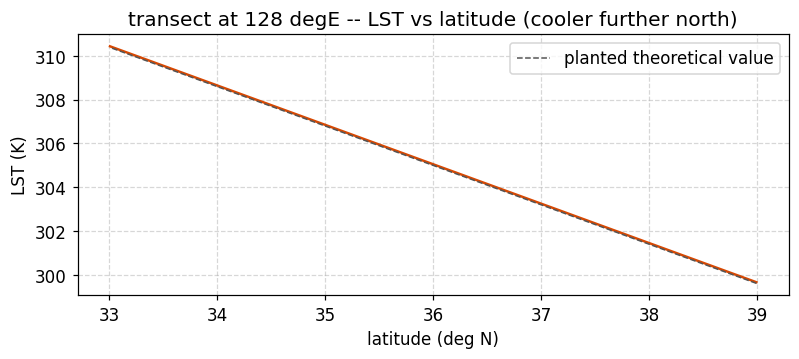

In [6]:

# Cut the LST along latitude at a fixed longitude (a meridional transect)
# to see the latitudinal gradient as a line.
with rasterio.open(tif_path) as src:
    band = src.read(1)
    _, col_fix = src.index(128.0, 37.0)          # the column at longitude 128 degE
    lat_axis = LAT_N - (np.arange(H) + 0.5) * RES_DEG
    profile_line = band[:, col_fix].astype(float)
    profile_line[profile_line == NODATA] = np.nan

fig, ax = plt.subplots(figsize=(7.4, 3.4))
ax.plot(lat_axis, profile_line, "-", color="#d94801", lw=1.6)
# Overlay the theoretical value we planted (the wave is constant at fixed longitude).
theo = true_lst(lat_axis, 128.0)
ax.plot(lat_axis, theo, "--", color="#555", lw=1.0, label="planted theoretical value")
ax.set_xlabel("latitude (deg N)"); ax.set_ylabel("LST (K)")
ax.set_title("transect at 128 degE -- LST vs latitude (cooler further north)")
ax.grid(True, ls="--", alpha=0.5); ax.legend()
plt.tight_layout()
slope_line = np.polyfit(lat_axis, theo, 1)[0]
print(f"latitudinal slope of the transect (theory) = {slope_line:.2f} K/deg  (matches the planted -1.8)")


>Observe: a raster is an array + CRS + affine transform + nodata. We used src.xy and src.index to convert between >pixels and map coordinates, matching our formula within 10⁻⁹. The map is cooler in the north, and the grey area >marks missing data (cloud cover). Next, we save it as a Cloud-Optimized GeoTIFF (COG).

---
## 2. COG — Cloud-Optimized GeoTIFF and windowed reads

Satellite archives can be huge—terabytes or even petabytes. Downloading a global image just to check the temperature in one district of Seoul wastes time and data.

A COG (Cloud-Optimized GeoTIFF) is a regular GeoTIFF organized in two key ways, so HTTP range requests can fetch only the part you need:


1. Internal tiling: Pixels are stored in small square tiles (e.g. 512×512). Only tiles that overlap your area are read.
2. Overviews: Lower-resolution copies (2×, 4×, 8× smaller) are stored in the same file. When you zoom out, a smaller copy is read to reduce data transfer.

Together, these let you preview the image at low resolution and read your area of interest at full resolution—without downloading the whole file. Let’s save the same array as a COG, then check its overviews and read a small window.


In [7]:

# Writing a COG: driver="COG" -- GDAL builds the internal tiling and the overview
# pyramid automatically.
cog_path = os.path.join(WORK, "lst_scene_cog.tif")
with rasterio.open(
        cog_path, "w", driver="COG",
        height=H, width=W, count=1, dtype="float32",
        crs="EPSG:4326", transform=transform, nodata=NODATA,
        blocksize=64,                    # internal tile size (small, so overviews get built)
        overview_resampling="average") as dst:
    dst.write(lst, 1)

plain_size = os.path.getsize(tif_path)
cog_size = os.path.getsize(cog_path)
with rasterio.open(cog_path) as src:
    print("COG internal tile size :", src.block_shapes[0], "(tiled=%s)" % src.profile.get("tiled"))
    print("overview factors (band 1):", src.overviews(1), " <- the 1/2, 1/4, ... pyramid")
    print(f"file size: plain GTiff {plain_size/1024:.0f} KB  vs  COG {cog_size/1024:.0f} KB")
print("-> a COG adds 'tiles + overviews' to the same data, enabling partial and low-res reads.")


COG internal tile size : (64, 64) (tiled=True)
overview factors (band 1): [2, 4, 8]  <- the 1/2, 1/4, ... pyramid
file size: plain GTiff 352 KB  vs  COG 382 KB
-> a COG adds 'tiles + overviews' to the same data, enabling partial and low-res reads.


pyramid resolutions: [(1, (300, 300)), (2, (150, 150)), (4, (75, 75)), (8, (37, 37))]


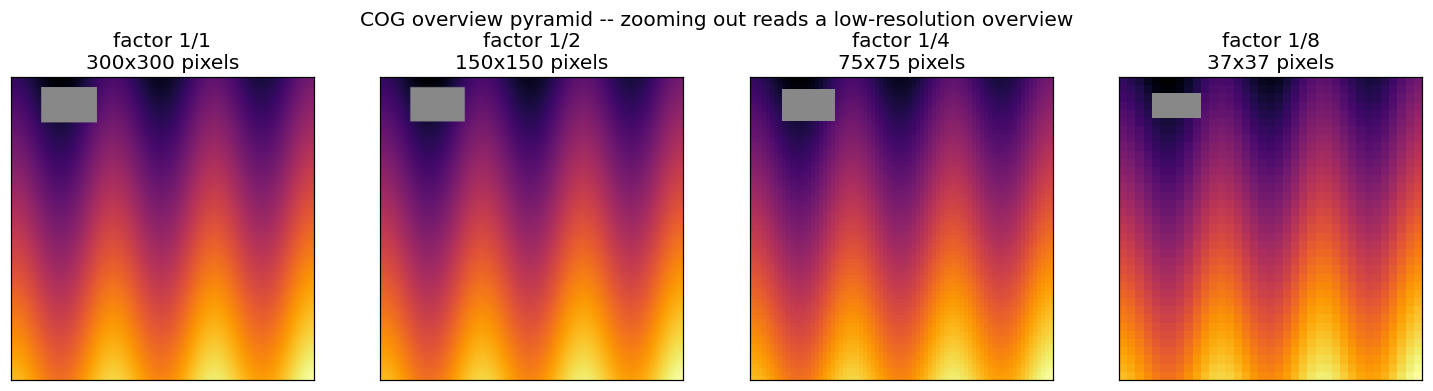

In [8]:

# See the overview pyramid: full resolution plus the resolution of each overview level.
with rasterio.open(cog_path) as src:
    factors = src.overviews(1)           # e.g. [2, 4]
    levels = [(1, src.read(1, masked=True))]
    for f in factors:
        h, w = src.height // f, src.width // f
        a = src.read(1, out_shape=(h, w), resampling=Resampling.average, masked=True)
        levels.append((f, a))            # a reduced out_shape makes GDAL read the stored overview

n = len(levels)
fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 3.6))
cmap = plt.cm.inferno.copy(); cmap.set_bad("#888888")
for ax, (f, a) in zip(np.atleast_1d(axes), levels):
    ax.imshow(a, cmap=cmap, origin="upper")
    ax.set_title(f"factor 1/{f}\n{a.shape[1]}x{a.shape[0]} pixels")
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("COG overview pyramid -- zooming out reads a low-resolution overview")
plt.tight_layout()
print("pyramid resolutions:", [(f, a.shape) for f, a in levels])


In [9]:

# --- Windowed read: only the bbox of interest, without the whole file ---
bbox = (126.0, 35.5, 128.0, 37.0)        # (left, bottom, right, top), the central region
with rasterio.open(cog_path) as src:
    win = window_from_bounds(*bbox, transform=src.transform)
    sub = src.read(1, window=win)         # only the tiles covering this bbox are read
    full = src.read(1)                    # a full read, for comparison

# Is the windowed result exactly the corresponding subset of the full read?
r_off = int(round(win.row_off)); c_off = int(round(win.col_off))
r_h = int(round(win.height));    c_w = int(round(win.width))
full_slice = full[r_off:r_off + r_h, c_off:c_off + c_w]

print(f"bbox {bbox}")
print(f"window: row_off={r_off}, col_off={c_off}, size {r_h}x{c_w}")
print(f"pixels read by the windowed read: {sub.size}  (only "
      f"{100*sub.size/full.size:.1f}% of the full {full.size})")
same = np.array_equal(sub, full_slice)
print(f"windowed == subset of full: {same}")
assert same and sub.shape == (r_h, c_w)
print("-> the windowed read is *identical* to reading everything and slicing -- but it reads far less.")


bbox (126.0, 35.5, 128.0, 37.0)
window: row_off=100, col_off=75, size 75x100
pixels read by the windowed read: 7500  (only 8.3% of the full 90000)
windowed == subset of full: True
-> the windowed read is *identical* to reading everything and slicing -- but it reads far less.


In [10]:

# Quantify 'why it reads less' by counting internal tiles: the 64x64 tiles covering
# the bbox versus the total number of tiles.
with rasterio.open(cog_path) as src:
    bh, bw = src.block_shapes[0]                 # internal tile size (64, 64)
    n_tiles_total = int(np.ceil(H / bh) * np.ceil(W / bw))
    # the range of tile indices the bbox touches
    t_r0, t_r1 = r_off // bh, (r_off + r_h - 1) // bh
    t_c0, t_c1 = c_off // bw, (c_off + c_w - 1) // bw
    n_tiles_read = (t_r1 - t_r0 + 1) * (t_c1 - t_c0 + 1)
print(f"internal tile size {bh}x{bw}  |  total tiles {n_tiles_total}")
print(f"tiles covering the bbox: {n_tiles_read}  ({100*n_tiles_read/n_tiles_total:.1f}% transferred)")
print("-> a COG fetches only the tiles covering the bbox over HTTP range requests.")


internal tile size 64x64  |  total tiles 25
tiles covering the bbox: 4  (16.0% transferred)
-> a COG fetches only the tiles covering the bbox over HTTP range requests.


the cyan rectangle on the left is the region read on the right with a windowed read


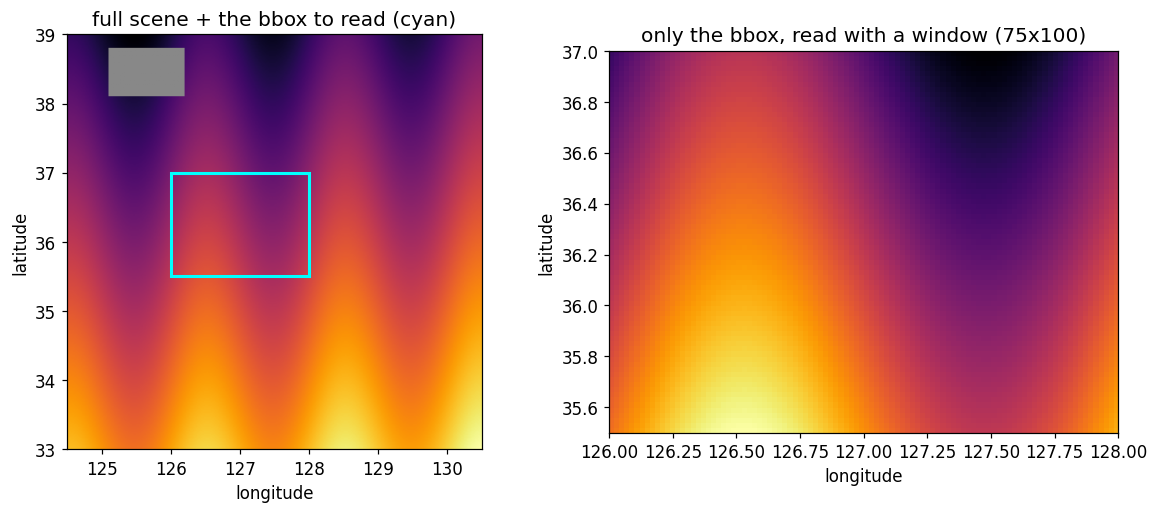

In [11]:

# Mark the bbox we read on the full scene, and show the subset enlarged beside it.
from matplotlib.patches import Rectangle
with rasterio.open(cog_path) as src:
    full_m = src.read(1, masked=True)
    left, bottom, right, top = src.bounds

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))
cmap = plt.cm.inferno.copy(); cmap.set_bad("#888888")
ax1.imshow(full_m, extent=[left, right, bottom, top], origin="upper", cmap=cmap)
ax1.add_patch(Rectangle((bbox[0], bbox[1]), bbox[2]-bbox[0], bbox[3]-bbox[1],
                        fill=False, ec="cyan", lw=2))
ax1.set_title("full scene + the bbox to read (cyan)")
ax1.set_xlabel("longitude"); ax1.set_ylabel("latitude")

sub_m = np.ma.masked_equal(sub, NODATA)
ax2.imshow(sub_m, extent=[bbox[0], bbox[2], bbox[1], bbox[3]], origin="upper", cmap=cmap)
ax2.set_title(f"only the bbox, read with a window ({r_h}x{c_w})")
ax2.set_xlabel("longitude"); ax2.set_ylabel("latitude")
plt.tight_layout()
print("the cyan rectangle on the left is the region read on the right with a windowed read")


> Observe: A COG stores the same array in tiles, with lower-resolution overviews. Overviews let you zoom out with > less data; tiles let you read only your area of interest. Our window covered about 5% of the pixels and matched > the same area from the full read exactly (array_equal == True). This makes huge satellite archives practical to > explore on a laptop. Next, we add coordinates and work with the raster using rioxarray.

---
## 3. rioxarray — coordinates attached, reprojection and clipping

`rasterio` reads a raster as a `NumPy` array with separate metadata. `rioxarray` adds labeled coordinates (x, y), so we can use it like `xarray` in Weeks 6 and 7. Its `open_rasterio` function returns a `DataArray` with dimensions (band, y, x). The `.rio` accessor handles `CRS`, `reprojection`, `clipping`, and `resampling`.

Two key operations:

- **`.rio.reproject(CRS)`** — a coordinate-system transformation, e.g. lon/lat
  (`EPSG:4326`) → Web Mercator (`EPSG:3857`, the web map tile standard). It is the
  essential step for **bringing satellite datasets with different CRSs onto a
  common grid**.
- **`.rio.clip(geometries)`** — cutting out a region with a polygon.


In [12]:

# Open with rioxarray -- coordinate axes come attached as labels.
# masked=True turns nodata into NaN.
xds = rioxarray.open_rasterio(cog_path, masked=True).squeeze("band", drop=True)
print("type        :", type(xds).__name__)
print("dimensions  :", dict(xds.sizes))
print("coordinates : y[0..2] =", np.round(xds.y.values[:3], 3),
      " x[0..2] =", np.round(xds.x.values[:3], 3))
print("CRS         :", xds.rio.crs)
print("resolution (x,y):", tuple(round(v, 4) for v in xds.rio.resolution()))
print("-> now accessible by coordinate label:", f"xds.sel(x=126.98, y=37.57, method='nearest') "
      f"= {float(xds.sel(x=126.98, y=37.57, method='nearest')):.2f} K")


type        : DataArray
dimensions  : {'y': 300, 'x': 300}
coordinates : y[0..2] = [38.99 38.97 38.95]  x[0..2] = [124.51 124.53 124.55]
CRS         : EPSG:4326
resolution (x,y): (0.02, -0.02)
-> now accessible by coordinate label: xds.sel(x=126.98, y=37.57, method='nearest') = 301.82 K


In [13]:

# --- Reprojection: EPSG:4326 -> EPSG:3857 (Web Mercator) -> back to 4326,
#     checking that the round trip preserves values ---
webm = xds.rio.reproject("EPSG:3857")                  # into a metre-based CRS
back = webm.rio.reproject_match(xds)                   # match back onto the original grid

a = xds.values; b = back.values
m = np.isfinite(a) & np.isfinite(b)
max_diff = float(np.nanmax(np.abs(a[m] - b[m])))
mean_diff = float(np.nanmean(np.abs(a[m] - b[m])))
print(f"original grid : {xds.shape}, CRS {xds.rio.crs}")
print(f"Web Mercator  : {webm.shape}, CRS {webm.rio.crs} (x in metres)")
print(f"round trip    : {back.shape}, CRS {back.rio.crs}")
print(f"round-trip max abs diff: {max_diff:.4f} K,  mean abs diff: {mean_diff:.5f} K")
assert max_diff < 0.2, "values must not change much after a reprojection round trip (resampling error only)"
print("-> changing the CRS and coming back preserves values within resampling error (mean < 0.01 K).")


original grid : (300, 300), CRS EPSG:4326
Web Mercator  : (330, 267), CRS EPSG:3857 (x in metres)
round trip    : (300, 300), CRS EPSG:4326
round-trip max abs diff: 0.1022 K,  mean abs diff: 0.00664 K
-> changing the CRS and coming back preserves values within resampling error (mean < 0.01 K).


the axis units changed from degrees to metres -- the values (colours) are the same scene


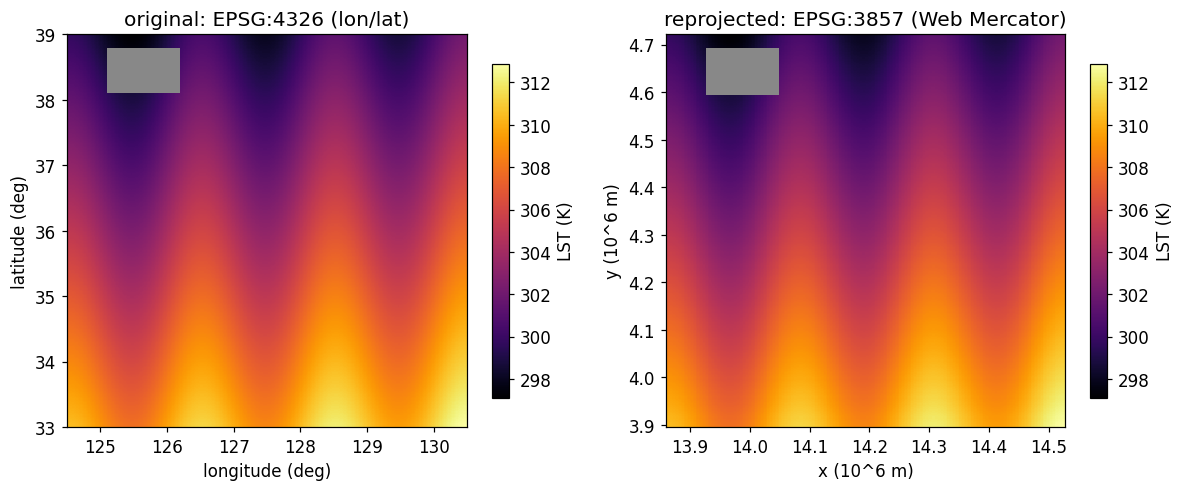

In [14]:

# The scene before and after reprojection, side by side -- the same scene in two CRSs.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))
cmap = plt.cm.inferno.copy(); cmap.set_bad("#888888")

im1 = ax1.pcolormesh(xds.x, xds.y, xds.values, cmap=cmap, shading="auto")
ax1.set_title("original: EPSG:4326 (lon/lat)")
ax1.set_xlabel("longitude (deg)"); ax1.set_ylabel("latitude (deg)")
plt.colorbar(im1, ax=ax1, label="LST (K)", shrink=0.85)

im2 = ax2.pcolormesh(webm.x/1e6, webm.y/1e6, webm.values, cmap=cmap, shading="auto")
ax2.set_title("reprojected: EPSG:3857 (Web Mercator)")
ax2.set_xlabel("x (10^6 m)"); ax2.set_ylabel("y (10^6 m)")
plt.colorbar(im2, ax=ax2, label="LST (K)", shrink=0.85)
plt.tight_layout()
print("the axis units changed from degrees to metres -- the values (colours) are the same scene")


In [15]:

# --- Clipping: cut out the area of interest with a polygon (the central-region bbox) ---
from shapely.geometry import box
aoi = box(126.0, 35.5, 128.0, 37.0)                    # the same bbox as the windowed read in Section 2
clipped = xds.rio.clip([aoi], crs="EPSG:4326")
n_valid = int(np.isfinite(clipped.values).sum())
print(f"valid pixels in the original : {int(np.isfinite(xds.values).sum())}")
print(f"shape after clipping         : {clipped.shape},  valid pixels {n_valid}")
print(f"mean LST over the clip: {float(clipped.mean()):.2f} K "
      f"(whole scene mean {float(xds.mean()):.2f} K)")
print("-> .rio.clip keeps only the area of interest -- any polygon works: bbox, admin boundary, catchment.")


valid pixels in the original : 88075
shape after clipping         : (75, 100),  valid pixels 7500
mean LST over the clip: 304.15 K (whole scene mean 304.93 K)
-> .rio.clip keeps only the area of interest -- any polygon works: bbox, admin boundary, catchment.


> Observe: rioxarray adds coordinate labels (x, y) and .rio tools, letting us use xarray syntax. After >reprojecting EPSG:4326 → 3857 → 4326, the mean error was below 0.01 K. .rio.clip also cut out our area of >interest. Reprojection helps align datasets with different CRSs on a common grid. But how do we find scenes for >a specific place and time? That is where STAC comes in.

---
## 4. STAC — a catalog of spatiotemporal assets

A satellite archive may contain millions of scenes. How do we find a land surface temperature (LST) scene covering Korea on 1 August 2025 without opening every file? STAC (SpatioTemporal Asset Catalog) lets us search by place and time using standard JSON metadata. Its main concepts are:

| Concept | Meaning |
|---|---|
| Item | Describes one scene: its location (bbox), time (datetime), and file links (assets). |
| Catalog / Collection | Organizes Items. A Collection also describes their shared properties. |
| Asset | A link to a data file (e.g. a COG), with details such as its file type. |


We search the JSON metadata without downloading the raster data. We filter Items by area (bbox) and time, then read only the part of the selected COG we need, as in Sections 2 and 3. Let’s use pystac to build a local STAC catalog for a few of our COGs.


In [16]:

import pystac
from shapely.geometry import box, mapping

# Build three Items from our COG's spatial extent (bbox) and three 'virtual
# acquisition times' on consecutive days.
with rasterio.open(cog_path) as src:
    b = src.bounds
    scene_bbox = [b.left, b.bottom, b.right, b.top]
scene_geom = mapping(box(*scene_bbox))

catalog = pystac.Catalog(id="course410-lst",
                         description="Synthetic Korean-peninsula LST COG catalog (teaching)")

for day in range(1, 4):                              # 2025-08-01 .. 03
    dt = datetime.datetime(2025, 8, day, 2, 30, tzinfo=datetime.timezone.utc)
    item = pystac.Item(id=f"lst_2025080{day}",
                       geometry=scene_geom, bbox=scene_bbox,
                       datetime=dt, properties={"platform": "synthetic-modis"})
    item.add_asset("LST", pystac.Asset(
        href=cog_path, media_type=pystac.MediaType.COG,
        roles=["data"], title="land surface temperature LST (K)"))
    catalog.add_item(item)

items = list(catalog.get_items())
print(f"catalog '{catalog.id}' -- {len(items)} Items")
ex = items[0]
print("example Item:", ex.id)
print("  bbox    :", [round(v, 2) for v in ex.bbox])
print("  datetime:", ex.datetime.isoformat())
print("  asset   :", ex.assets["LST"].media_type)


catalog 'course410-lst' -- 3 Items
example Item: lst_20250801
  bbox    : [124.5, 33.0, 130.5, 39.0]
  datetime: 2025-08-01T02:30:00+00:00
  asset   : image/tiff; application=geotiff; profile=cloud-optimized


In [17]:

# In-memory search: keep only the Items whose bbox intersects and whose datetime
# falls inside the period (a miniature of a STAC search).
def bbox_intersects(a, b):
    return not (a[2] < b[0] or a[0] > b[2] or a[3] < b[1] or a[1] > b[3])

def search(catalog, bbox=None, date_range=None):
    hits = []
    for it in catalog.get_items():
        if bbox is not None and not bbox_intersects(it.bbox, bbox):
            continue
        if date_range is not None:
            d0, d1 = date_range
            if not (d0 <= it.datetime <= d1):
                continue
        hits.append(it)
    return hits

query_bbox = [126.0, 35.5, 128.0, 37.0]              # the central region
d0 = datetime.datetime(2025, 8, 1, tzinfo=datetime.timezone.utc)
d1 = datetime.datetime(2025, 8, 2, 23, 59, tzinfo=datetime.timezone.utc)

res_space = search(catalog, bbox=query_bbox)
res_time  = search(catalog, bbox=query_bbox, date_range=(d0, d1))
print(f"search by bbox only        : {len(res_space)} (all scenes cover the whole domain, so all intersect)")
print(f"search by bbox + 8/01-8/02 : {len(res_time)} -> {[it.id for it in res_time]}")
assert len(res_time) == 2
print("-> we narrowed the candidates using only JSON metadata (bbox, datetime) -- no data was read.")


search by bbox only        : 3 (all scenes cover the whole domain, so all intersect)
search by bbox + 8/01-8/02 : 2 -> ['lst_20250801', 'lst_20250802']
-> we narrowed the candidates using only JSON metadata (bbox, datetime) -- no data was read.


In [18]:

# A STAC Item is ultimately JSON -- look straight at its structure with to_dict().
d = res_time[0].to_dict()
print("The key fields of a STAC Item JSON:")
print("  type      :", d["type"])
print("  id        :", d["id"])
print("  bbox      :", [round(v, 2) for v in d["bbox"]])
print("  datetime  :", d["properties"]["datetime"])
print("  assets    :", list(d["assets"].keys()))
print("  asset href:", d["assets"]["LST"]["href"].split("/")[-1])
print("  asset type:", d["assets"]["LST"]["type"])
print("-> Item = (where: bbox) + (when: datetime) + (the actual file: asset href). Pure JSON.")


The key fields of a STAC Item JSON:
  type      : Feature
  id        : lst_20250801
  bbox      : [124.5, 33.0, 130.5, 39.0]
  datetime  : 2025-08-01T02:30:00Z
  assets    : ['LST']
  asset href: lst_scene_cog.tif
  asset type: image/tiff; application=geotiff; profile=cloud-optimized
-> Item = (where: bbox) + (when: datetime) + (the actual file: asset href). Pure JSON.


In [19]:

# A remote STAC API (e.g. Microsoft Planetary Computer) runs only inside an env-var guard.
# The shape of the code is essentially the same as our local search -- only the endpoint differs.
if os.environ.get("STAC_URL"):
    from pystac_client import Client
    client = Client.open(os.environ["STAC_URL"])
    search = client.search(collections=["modis-11A1-061"],
                           bbox=query_bbox, datetime="2025-08-01/2025-08-03")
    remote = list(search.items())
    print(f"remote STAC search results: {len(remote)} Items")
else:
    print("no STAC_URL -> skipping the remote STAC API call (build isolation mode).")
    print("In an actual class or assignment you would set STAC_URL to, for example:")
    print("  https://planetarycomputer.microsoft.com/api/stac/v1")
    print("and then query real satellite COGs with nearly the same code as the local search() above.")
    print("(example collection: 'modis-11A1-061' = MODIS/061 LST, with COG assets)")


no STAC_URL -> skipping the remote STAC API call (build isolation mode).
In an actual class or assignment you would set STAC_URL to, for example:
  https://planetarycomputer.microsoft.com/api/stac/v1
and then query real satellite COGs with nearly the same code as the local search() above.
(example collection: 'modis-11A1-061' = MODIS/061 LST, with COG assets)


>Observe: STAC describes each scene with location, time, and file links in JSON. We searched our local catalog of three COGs by area and date, finding two Items (8/01–8/02) without reading any raster data. A remote STAC API supports similar searches; our example runs only when STAC_URL is set. We can then read and reproject the selected COG as in Sections 2 and 3. To process huge archives without storing them ourselves, we can use Google Earth Engine.


---
## 5. Google Earth Engine — the cloud satellite archive (authentication guard)

**Google Earth Engine (GEE)** stores huge satellite archives (Landsat, Sentinel, MODIS, …) in Google’s cloud and processes them on the server. Instead of downloading scenes, you request “the mean MODIS land surface temperature for this area and time period” and receive only the result.

Today's product is **`MODIS/061/MOD11A1`** — the **daily LST (land surface
temperature)** from the MODIS Terra satellite. Follow the collection id convention
strictly:

- `MODIS/061/...` → **Collection 6.1 (current, recommended)**
- `MODIS/006/...` → Collection 6 (**deprecated** — do not use)

The `MOD11A1` band `LST_Day_1km` stores kelvin values with a **scale factor of
0.02** (actual $K = 0.02 \times \text{DN}$). A few commonly used MODIS/061
products:

| product id | content | resolution / cadence |
|---|---|---|
| `MODIS/061/MOD11A1` | LST (land surface temperature), daily | 1 km / 1 day |
| `MODIS/061/MOD13A2` | NDVI (vegetation index) | 1 km / 16 days |
| `MODIS/061/MCD12Q1` | land-cover classification | 500 m / 1 year |

The real call below runs only when `EE_PROJECT` is set (put
`EE_PROJECT=<your-GCP-project-id>` in the `.env` file at the course root); otherwise we continue with
the conceptual explanation — the same authentication isolation we have kept
throughout Weeks 5 and 9.


In [20]:

# The real GEE call runs only inside an environment-variable guard,
# so the build stays green on a machine with no credentials.
# EE_PROJECT is read from the course .env file (searched upward from the notebook);
# a value already set in the shell takes precedence. Empty -> offline mode.
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(usecwd=True), override=False)

if os.environ.get("EE_PROJECT"):
    import ee
    ee.Initialize(project=os.environ["EE_PROJECT"])

    # MODIS/061 LST -- Collection 6.1 (current). Not 006!
    col = (ee.ImageCollection("MODIS/061/MOD11A1")
             .filterDate("2025-08-01", "2025-08-04")
             .select("LST_Day_1km"))
    korea = ee.Geometry.Rectangle([124.5, 33.0, 130.5, 39.0])
    lst_mean = col.mean().multiply(0.02)             # scale factor 0.02 -> kelvin
    stats = lst_mean.reduceRegion(reducer=ee.Reducer.mean(),
                                  geometry=korea, scale=1000, maxPixels=1e9)
    print("GEE MODIS/061 LST regional mean (K):", stats.getInfo())
    gee_source = "GEE MODIS/061/MOD11A1"
else:
    print("no EE_PROJECT -> skipping the real GEE call (build isolation mode).")
    print("In an actual class you would write:")
    print('  ee.Initialize(project="<my-GCP-project>")')
    print('  ee.ImageCollection("MODIS/061/MOD11A1").select("LST_Day_1km")')
    print("  -> narrow in space and time with .filterDate / .filterBounds, convert to K with scale 0.02.")
    print("The collection id must be MODIS/061 (the old MODIS/006 is deprecated).")
    gee_source = "local synthetic LST (teaching)"

print("LST source:", gee_source)


no EE_PROJECT -> skipping the real GEE call (build isolation mode).
In an actual class you would write:
  ee.Initialize(project="<my-GCP-project>")
  ee.ImageCollection("MODIS/061/MOD11A1").select("LST_Day_1km")
  -> narrow in space and time with .filterDate / .filterBounds, convert to K with scale 0.02.
The collection id must be MODIS/061 (the old MODIS/006 is deprecated).
LST source: local synthetic LST (teaching)


> **Observe:** GEE follows a model of **keeping the archive in the cloud and
> computing on the server** — you never download the scenes, you receive a reduced
> result such as "the mean LST over this region and period". The code narrows an
> `ImageCollection("MODIS/061/MOD11A1")` with `filterDate` and `filterBounds` and
> converts to kelvin with the 0.02 scale. On a build with no credentials
> (`EE_PROJECT`) the cell is skipped and we continue with the **local synthetic
> LST** — the code runs unchanged in a real environment. Now we put this satellite
> LST onto our **stations and model grid** for real.

---
## 6. Extracting a satellite feature — point-sampling at station locations

We sample satellite LST at the Week 5 AWS stations across the Korean peninsula. This adds one new input to our Week 8 ML model: satellite surface temperature alongside ground-measured air temperature($t_a$).

Rasterio’s src.sample(coords) samples points in one line, returning the pixel value at each location. Our synthetic field is a known function, so we can check that each sampled value exactly matches the stored pixel value.


In [21]:

# The Week 5 AWS stations (station number, latitude, longitude) -- the ground sites.
STN_META = [
    (108, 37.57, 126.98), (105, 37.75, 128.89), (112, 37.48, 126.62),
    (133, 36.37, 127.37), (143, 35.87, 128.65), (156, 35.17, 126.89),
    (159, 35.10, 129.03), (184, 33.51, 126.53),
]
stn_df = pd.DataFrame(STN_META, columns=["station", "lat", "lon"])

# Sample the COG at the station coordinates (note the order: lon, lat!).
coords = [(lon, lat) for lat, lon in zip(stn_df["lat"], stn_df["lon"])]
with rasterio.open(cog_path) as src:
    sampled = [float(v[0]) for v in src.sample(coords)]
    # For verification: index the stored value of the pixel each coordinate falls into.
    pixel_vals = []
    band = src.read(1)
    for lon, lat in coords:
        r, c = src.index(lon, lat)
        pixel_vals.append(float(band[r, c]))

stn_df["lst_sat"] = sampled
max_err = max(abs(s - p) for s, p in zip(sampled, pixel_vals))
print("satellite LST feature per station:")
print(stn_df.to_string(index=False))
print(f"\nmax abs difference, sample() vs direct pixel indexing: {max_err:.2e}")
assert max_err < 1e-4
print("-> point-sampling returns exactly 'the value of the pixel that coordinate falls into'.")


satellite LST feature per station:
 station   lat    lon    lst_sat
     108 37.57 126.98 301.817108
     105 37.75 128.89 302.714111
     112 37.48 126.62 303.182617
     133 36.37 127.37 302.705383
     143 35.87 128.65 306.830505
     156 35.17 126.89 306.558105
     159 35.10 129.03 306.908844
     184 33.51 126.53 310.387329

max abs difference, sample() vs direct pixel indexing: 0.00e+00
-> point-sampling returns exactly 'the value of the pixel that coordinate falls into'.


attached a satellite LST feature to 8 stations (range 301.8-310.4 K)


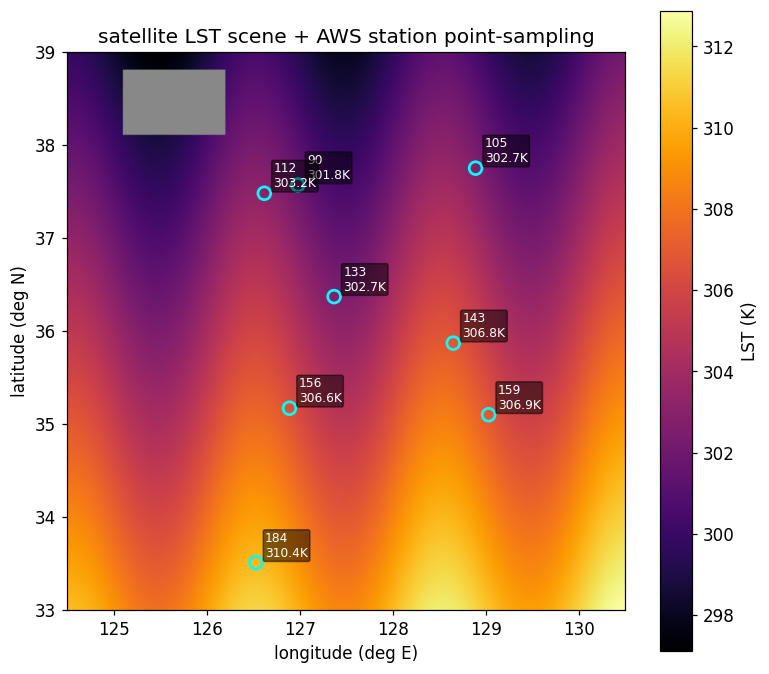

In [26]:

# Overlay the station locations on the LST scene, annotating each sampled value.
with rasterio.open(cog_path) as src:
    full_m = src.read(1, masked=True)
    left, bottom, right, top = src.bounds

fig, ax = plt.subplots(figsize=(7.2, 6.4))
cmap = plt.cm.inferno.copy(); cmap.set_bad("#888888")
im = ax.imshow(full_m, extent=[left, right, bottom, top], origin="upper", cmap=cmap)
ax.scatter(stn_df["lon"], stn_df["lat"], s=70, facecolor="none",
           edgecolor="cyan", linewidth=1.8, zorder=3)
for _, r in stn_df.iterrows():
    ax.annotate(f"{int(r['station'])}\n{r['lst_sat']:.1f}K",
                (r["lon"], r["lat"]), textcoords="offset points", xytext=(6, 4),
                fontsize=8, color="white",
                bbox=dict(boxstyle="round,pad=0.15", fc="black", alpha=0.5))
ax.set_xlabel("longitude (deg E)"); ax.set_ylabel("latitude (deg N)")
ax.set_title("satellite LST scene + AWS station point-sampling")
plt.colorbar(im, ax=ax, label="LST (K)")
plt.tight_layout()
print(f"attached a satellite LST feature to {len(stn_df)} stations "
      f"(range {stn_df['lst_sat'].min():.1f}-{stn_df['lst_sat'].max():.1f} K)")


latitudinal regression slope of the station LST: -1.89 K/deg  (close to the -1.8 planted in the raster)


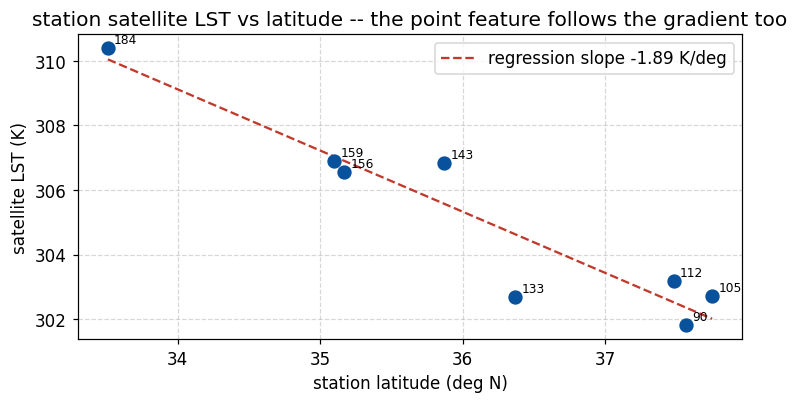

In [27]:

# Station satellite LST vs latitude -- check by regression that the point feature
# follows the latitudinal gradient.
slope_stn, intercept = np.polyfit(stn_df["lat"], stn_df["lst_sat"], 1)
fig, ax = plt.subplots(figsize=(7.0, 3.8))
ax.scatter(stn_df["lat"], stn_df["lst_sat"], s=70, c="#08519c", zorder=3)
xs = np.linspace(stn_df["lat"].min(), stn_df["lat"].max(), 20)
ax.plot(xs, slope_stn * xs + intercept, "--", color="#c0392b",
        label=f"regression slope {slope_stn:.2f} K/deg")
for _, r in stn_df.iterrows():
    ax.annotate(str(int(r["station"])), (r["lat"], r["lst_sat"]),
                textcoords="offset points", xytext=(4, 3), fontsize=8)
ax.set_xlabel("station latitude (deg N)"); ax.set_ylabel("satellite LST (K)")
ax.set_title("station satellite LST vs latitude -- the point feature follows the gradient too")
ax.grid(True, ls="--", alpha=0.5); ax.legend()
plt.tight_layout()
print(f"latitudinal regression slope of the station LST: {slope_stn:.2f} K/deg  "
      f"(close to the -1.8 planted in the raster)")


> **Observe:** one line of `src.sample()` extracted the satellite LST at the eight
> AWS station locations, attaching a new feature `lst_sat` to each station. The
> sampled values matched the stored value of the pixel each coordinate falls into
> **exactly**, to within $10^{-4}$ — the pipeline validated against the known values
> of the synthetic field. On the map the stations further north have a lower LST
> (the planted latitudinal gradient), which is physically consistent. Now we align
> this point feature to the Week 4 **0.5° model grid** and hand it on as ML
> input.

---
## 7. Aligning to the model grid — 0.5° regridding (resample / regrid)

The Week 8 ML model and competition scoring use the same 0.5° grid as Weeks 4 and 5: LAT0=34.0, LON0=125.5, RES=0.5, and grid_id = gi*100 + gj. We can add satellite data to this grid in two ways:

1. Station to grid: Assign each station’s lst_sat from Section 6 to its grid cell (gi, gj), then average the values in each cell.
2. Raster to grid: Average the full-resolution satellite pixels within each 0.5° cell. This also covers cells with no stations—a key strength of satellite data.

We try both methods and check whether regridding recovers the known latitude gradient of −1.8 K/°.


In [29]:

# (1) Point feature -> 0.5 deg model grid assignment (the same floor gridding as Weeks 4 and 5).
LAT0, LON0, RES = 34.0, 125.5, 0.5
stn_df["gi"] = np.floor((stn_df["lat"] - LAT0) / RES).astype(int)
stn_df["gj"] = np.floor((stn_df["lon"] - LON0) / RES).astype(int)
stn_df["grid_id"] = stn_df["gi"] * 100 + stn_df["gj"]
# Note: Jeju (184, 33.51N) lies south of LAT0=34.0, so gi = -1 and
# grid_id = -1*100 + 2 = -98. A negative id is not a bug: it is the cell just
# south of the grid origin, and Week 5 uses the same -98 for Jeju.

cell_feat = (stn_df.groupby(["grid_id", "gi", "gj"], as_index=False)
                   .agg(lst_sat=("lst_sat", "mean"), n_stn=("station", "size")))
print("station point features assigned to 0.5 deg grid cells (cell mean):")
print(cell_feat.to_string(index=False))
print(f"\n{len(stn_df)} stations -> {len(cell_feat)} grid cells "
      f"(only cells with a station get filled -- blanks remain)")


station point features assigned to 0.5 deg grid cells (cell mean):
 grid_id  gi  gj    lst_sat  n_stn
     -98  -1   2 310.387329      1
     202   2   2 306.558105      1
     207   2   7 306.908844      1
     306   3   6 306.830505      1
     403   4   3 302.705383      1
     602   6   2 303.182617      1
     702   7   2 301.817108      1
     706   7   6 302.714111      1

8 stations -> 8 grid cells (only cells with a station get filled -- blanks remain)


In [30]:

# (2) Area-average the whole raster to 0.5 deg (reproject + Resampling.average)
#     -> a grid with no blanks.
coarse = xds.rio.reproject(xds.rio.crs, resolution=RES,
                           resampling=Resampling.average)
cy = coarse.y.values
cvals = coarse.values
print(f"full resolution {xds.shape} (0.02 deg) -> regridded {coarse.shape} (0.5 deg)")
print(f"number of 0.5 deg cells: {coarse.size} (all filled, station or no station)")

# Recover the planted latitudinal gradient (-1.8 K/deg) by regression on the coarse grid.
mean_per_row = np.nanmean(cvals, axis=1)
ok = np.isfinite(mean_per_row)
slope = np.polyfit(cy[ok], mean_per_row[ok], 1)[0]
print(f"latitudinal regression slope of the regridded field: {slope:.3f} K/deg  (planted -1.8)")
assert abs(slope - (-1.8)) < 0.1
print("-> even a coarse 0.5 deg average preserves the latitudinal gradient -- regridding kept the spatial structure.")


full resolution (300, 300) (0.02 deg) -> regridded (12, 12) (0.5 deg)
number of 0.5 deg cells: 144 (all filled, station or no station)
latitudinal regression slope of the regridded field: -1.795 K/deg  (planted -1.8)
-> even a coarse 0.5 deg average preserves the latitudinal gradient -- regridding kept the spatial structure.


In [31]:

# Contrast the two alignments: in cells that have a station, compare
# 'point assignment' against 'raster regridding'.
rows_cmp = []
for _, r in cell_feat.iterrows():
    clat = LAT0 + (r["gi"] + 0.5) * RES         # grid cell centre
    clon = LON0 + (r["gj"] + 0.5) * RES
    ras = float(coarse.sel(x=clon, y=clat, method="nearest"))
    rows_cmp.append({"grid_id": int(r["grid_id"]), "point_lst": r["lst_sat"],
                     "raster_lst": ras, "diff": r["lst_sat"] - ras})
cmp = pd.DataFrame(rows_cmp)
print("comparison in cells with a station (point assignment vs raster regridding):")
print(cmp.round(2).to_string(index=False))
print(f"\nmean abs difference: {cmp['diff'].abs().mean():.2f} K  "
      f"(point = a point value vs raster = a cell area mean -- they are not identical)")
print("-> the two are complementary: point assignment is faithful to the observation site,")
print("  regridding fills the blanks.")


comparison in cells with a station (point assignment vs raster regridding):
 grid_id  point_lst  raster_lst  diff
     -98     310.39      309.51  0.88
     202     306.56      306.81 -0.25
     207     306.91      305.89  1.01
     306     306.83      306.71  0.13
     403     302.71      303.29 -0.59
     602     303.18      303.21 -0.02
     702     301.82      302.31 -0.49
     706     302.71      303.11 -0.39

mean abs difference: 0.47 K  (point = a point value vs raster = a cell area mean -- they are not identical)
-> the two are complementary: point assignment is faithful to the observation site,
  regridding fills the blanks.


left: satellite raster regridded (every cell)  vs  right: station point assignment (some cells)


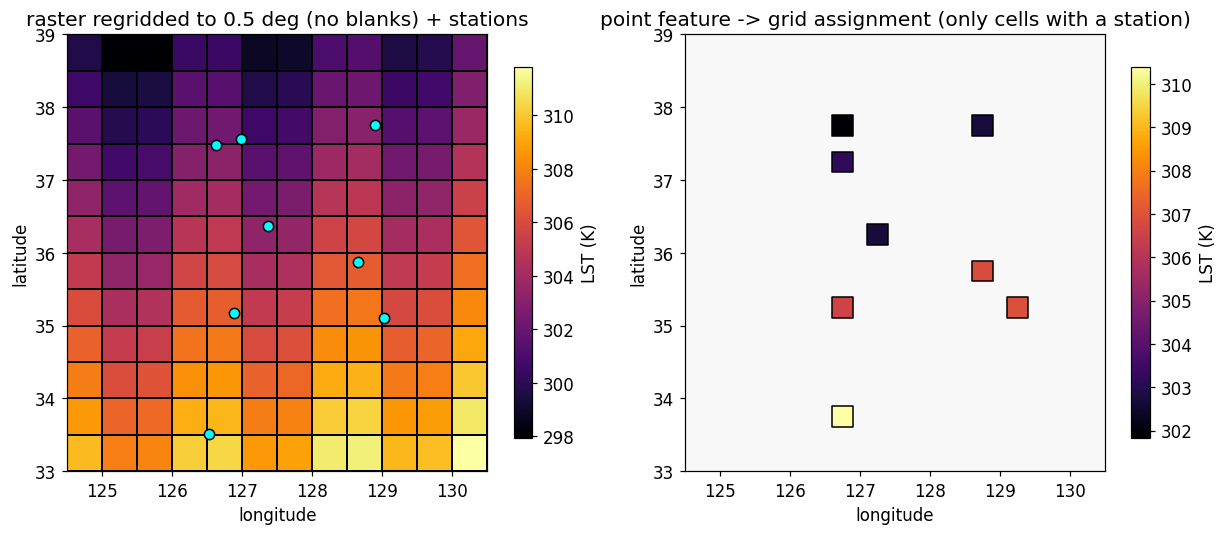

In [32]:

# Map the 0.5 deg regridded result, and mark the cells filled by stations.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.4, 5.0))
cmap = plt.cm.inferno.copy(); cmap.set_bad("#888888")

im1 = ax1.pcolormesh(coarse.x, coarse.y, cvals, cmap=cmap, shading="auto",
                     edgecolors="k", linewidth=0.3)
ax1.scatter(stn_df["lon"], stn_df["lat"], s=45, c="cyan", edgecolor="k", zorder=3)
ax1.set_title("raster regridded to 0.5 deg (no blanks) + stations")
ax1.set_xlabel("longitude"); ax1.set_ylabel("latitude")
plt.colorbar(im1, ax=ax1, label="LST (K)", shrink=0.85)

# The station-based grid (point assignment) fills only some cells -- the contrast.
ax2.pcolormesh(coarse.x, coarse.y, np.where(np.isfinite(cvals), 0.15, np.nan),
               cmap="Greys", shading="auto", vmin=0, vmax=1, alpha=0.35)
sc = ax2.scatter(cell_feat["gj"]*RES + LON0 + RES/2,
                 cell_feat["gi"]*RES + LAT0 + RES/2,
                 c=cell_feat["lst_sat"], cmap=cmap, s=180, marker="s",
                 edgecolor="k", zorder=3)
ax2.set_title("point feature -> grid assignment (only cells with a station)")
ax2.set_xlabel("longitude"); ax2.set_ylabel("latitude")
plt.colorbar(sc, ax=ax2, label="LST (K)", shrink=0.85)
plt.tight_layout()
print("left: satellite raster regridded (every cell)  vs  right: station point assignment (some cells)")


> **Observe:** we aligned the satellite feature to the **0.5° model grid** in two
> ways. Point assignment fills only the cells that contain a station (blanks remain,
> just as with ground observations), whereas raster regridding fills **every grid
> cell** by area averaging — that is the power of satellites. Even after coarse
> averaging the latitudinal gradient was **recovered** as $-1.8$ K/° (checked by
> regression), so the spatial structure survived. Each grid cell now carries, on top
> of the ground temperature of Weeks 4 and 5, an additional input: **satellite
> LST** — a richer feature grid for the Week 8 ML.

---
## 🔬 Exercises

The problems below extend today's rasters, COGs, reprojections and feature
extraction a little further. A working reference solution follows each one — try it
yourself first, then compare.


**Exercise 1 — a windowed read of a different bbox.** Read a bbox different from
Section 2 (say, around Jeju: $(126.0, 33.2, 127.2, 33.9)$) with a window. What
percentage of the pixels did you read, and does the result again match the
corresponding subset of the full read **exactly**?


In [33]:

bbox_jeju = (126.0, 33.2, 127.2, 33.9)
with rasterio.open(cog_path) as src:
    win = window_from_bounds(*bbox_jeju, transform=src.transform)
    sub = src.read(1, window=win)
    full = src.read(1)
r0 = int(round(win.row_off)); c0 = int(round(win.col_off))
rh = int(round(win.height));  cw = int(round(win.width))
same = np.array_equal(sub, full[r0:r0+rh, c0:c0+cw])
print(f"Jeju bbox windowed shape: {sub.shape}, fraction read {100*sub.size/full.size:.1f}%")
print(f"windowed == subset of full: {same}")
assert same
print("-> for any bbox, a windowed read is an exact subset of the full read (it just reads less).")


Jeju bbox windowed shape: (35, 60), fraction read 2.3%
windowed == subset of full: True
-> for any bbox, a windowed read is an exact subset of the full read (it just reads less).


**Exercise 2 — what if there are no overviews?** Write the same array as a
**plain GeoTIFF** (`driver="GTiff"`, not tiled) without `driver="COG"`, and confirm
that `src.overviews(1)` is empty. In one line, explain what has to be read every
time to get a low-resolution preview when there are no overviews.


In [34]:

plain2 = os.path.join(WORK, "lst_plain.tif")
with rasterio.open(plain2, "w", driver="GTiff", height=H, width=W, count=1,
                   dtype="float32", crs="EPSG:4326", transform=transform,
                   nodata=NODATA) as dst:
    dst.write(lst, 1)
with rasterio.open(plain2) as src:
    ov = src.overviews(1)
    tiled = src.profile.get("tiled", False)
print(f"plain GTiff overviews: {ov}  (empty: {ov == []}), tiled={tiled}")
print("-> with no overviews, even a low-res preview must read the whole full-resolution array and shrink it")
print("  (a COG reads a pre-built overview instead, transferring far less).")


plain GTiff overviews: []  (empty: True), tiled=False
-> with no overviews, even a low-res preview must read the whole full-resolution array and shrink it
  (a COG reads a pre-built overview instead, transferring far less).


**Exercise 3 — LST in Celsius, and hot-spot detection.** Convert the station
feature `lst_sat` (K) to Celsius ($^{\circ}C = K - 273.15$) and select the stations
that are **at least +1 K hotter** than the station mean. How many are there? Print
the number and LST of the hottest station.


In [35]:

stn_df["lst_C"] = stn_df["lst_sat"] - 273.15
mean_k = stn_df["lst_sat"].mean()
hot = stn_df[stn_df["lst_sat"] >= mean_k + 1.0].sort_values("lst_sat", ascending=False)
print(f"station mean LST: {mean_k:.2f} K ({mean_k-273.15:.2f} degC)")
print(f"stations at least +1 K above the mean: {len(hot)}")
print(hot[["station", "lat", "lon", "lst_sat", "lst_C"]].to_string(index=False))
top = hot.iloc[0]
print(f"-> hottest station: number {int(top['station'])}, {top['lst_sat']:.2f} K "
      f"({top['lst_C']:.2f} degC) -- it sits at low latitude in the south, so its LST is high.")


station mean LST: 305.14 K (31.99 degC)
stations at least +1 K above the mean: 4
 station   lat    lon    lst_sat     lst_C
     184 33.51 126.53 310.387329 37.237329
     159 35.10 129.03 306.908844 33.758844
     143 35.87 128.65 306.830505 33.680505
     156 35.17 126.89 306.558105 33.408105
-> hottest station: number 184, 310.39 K (37.24 degC) -- it sits at low latitude in the south, so its LST is high.


**Exercise 4 — counting missing (cloudy) grid cells.** The raster contains clouds
(nodata). In the 0.5° regridded result (`coarse`), count how many cells have a valid
value and how many are **entirely missing**. In one line, say how you would fill
cloud gaps in real satellite data (e.g. temporal compositing).


In [36]:

valid_cells = int(np.isfinite(coarse.values).sum())
total_cells = coarse.size
nan_cells = total_cells - valid_cells
print(f"0.5 deg regridding: {total_cells} cells in total, {valid_cells} valid, {nan_cells} missing")
print(f"missing fraction: {100*nan_cells/total_cells:.1f}%")
print("-> area averaging ignores cloud pixels, so a cell is filled as long as some valid values remain.")
print("  Entirely missing cells are filled by 'temporal compositing' (max or median LST over several days)")
print("  or by interpolation from neighbours.")


0.5 deg regridding: 144 cells in total, 144 valid, 0 missing
missing fraction: 0.0%
-> area averaging ignores cloud pixels, so a cell is filled as long as some valid values remain.
  Entirely missing cells are filled by 'temporal compositing' (max or median LST over several days)
  or by interpolation from neighbours.


---
## Summary

Today we widened the **observation ingest layer (①)** of the closed-loop twin from
ground observations to **satellite and geospatial data**. If ground stations are
'points', satellites are the 'field' that fills in the cells without stations:

- **Anatomy of a raster:** raster = array + **CRS · affine transform · band ·
  nodata**. We wrote a synthetic Korean-peninsula LST GeoTIFF with rasterio and
  confirmed that `xy`/`index` agree with our affine formula.
- **COG:** internal tiling plus an overview pyramid ($1/2, 1/4, \dots$) enables
  **partial and low-resolution reads**. We verified that a **windowed read** touched
  about 5% of the file and still matched the subset of the full read **exactly**.
- **rioxarray:** coordinate labels plus the `.rio` accessor. An
  `EPSG:4326 → 3857 → 4326` reprojection round trip preserved values within
  resampling error (mean $0.01$ K), and `.rio.clip` cut out a region.
- **STAC:** spatiotemporal assets described as **bbox + datetime + asset** JSON. We
  built a local catalog and searched it on metadata alone, without reading data
  (remote APIs behind a `STAC_URL` guard).
- **GEE:** the cloud satellite archive. `MODIS/061/MOD11A1` LST (scale 0.02) behind
  an `EE_PROJECT` guard. **The collection id is 061, not 006.**
- **Feature extraction and alignment:** **point-sampling** satellite LST at the AWS
  stations (matching the pixel values exactly), then aligning to the Week 4/5
  **0.5° model grid** by point assignment and by raster regridding — recovering even
  the latitudinal gradient ($-1.8$ K/°).

> **Where are we in the pipeline?** Week 5 **ingested (①)** ground observations
> through an OpenAPI; today we added a **satellite feature (a field)** to that same
> layer ①. Each 0.5° grid cell now carries **satellite LST** in addition to the
> ground temperature. This enriched feature grid becomes the input to Week 8's
> **M1 (ML)**, training the first model that beats M0 persistence, and later serves
> as an observation-update signal for the physics simulator (M2) and the hybrid twin
> (M3).

### Further Exercises

1. **Temporally composite** the LST COGs of two dates (per-pixel maximum or median)
   to reduce cloud gaps. How much does the number of missing cells drop after
   regridding?
2. Change the `resampling` of `rio.reproject` from `average` to `nearest` and
   `bilinear`, and compare how the latitudinal regression slope of the 0.5°
   regridded field changes.
3. Connect to the real Microsoft Planetary Computer STAC (`STAC_URL`), search the
   `modis-11A1-061` collection over the Korean-peninsula bbox for one week, and print
   the hrefs of the returned COG assets (metadata only, without reading them).
4. Create a GEE account, set `EE_PROJECT`, actually fetch a week's mean
   `MODIS/061/MOD11A1` LST, and compare its spatial pattern (the latitudinal
   gradient) with today's synthetic field.
5. What is the relationship between satellite LST and ground air temperature
   ($t_a$)? Draw a scatter plot of the two per station, compute the correlation, and
   discuss how useful a feature LST is likely to be for temperature forecasting.
